In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

C:\Users\Thidar Khaing\.conda\envs\deepenv\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
dataset_path = "D:/Deep Learning for Image/dataset"

img_height = 128
img_width = 128
batch_size = 32

num_classes = 5

In [3]:
# Load 70% training data
train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="training",
    seed=21,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode="categorical"
)

# Load remaining 30% data
temp_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="validation",
    seed=21,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode="categorical"
)

Found 1181 files belonging to 5 classes.
Using 827 files for training.
Found 1181 files belonging to 5 classes.
Using 354 files for validation.


In [4]:
# 15% validation and 15% testing
val_batches = tf.data.experimental.cardinality(temp_ds)

test_ds = temp_ds.take(val_batches // 2)
val_ds = temp_ds.skip(val_batches // 2)

class_names = train_ds.class_names

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Classes: ['bike', 'dogs', 'flowers', 'horses', 'human']
Number of classes: 5


In [5]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

val_ds = val_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

test_ds = test_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

# Improve loading performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

In [6]:
model = Sequential([

    # Input layer
    Input(shape=(128, 128, 3)),

    # Convolution Layer 1
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    # Convolution Layer 2
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    # Convolution Layer 3
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    # Flatten Layer
    Flatten(),

    # Fully Connected Layer
    Dense(128, activation='relu'),
    Dropout(0.5),

    # Classification Layer
    Dense(5, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 128, 128, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 64, 64, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 32, 32, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 32768)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       4,194,432 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 5)                   │             645 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,288,325 (16.36 MB)

 Trainable params: 4,288,325 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [8]:
epochs = 5

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)

Epoch 1/5


C:\Users\Thidar Khaing\.conda\envs\deepenv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


26/26 ━━━━━━━━━━━━━━━━━━━━ 14s 458ms/step - accuracy: 0.3748 - loss: 1.4824 - val_accuracy: 0.5617 - val_loss: 1.1364
Epoch 2/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 9s 326ms/step - accuracy: 0.5635 - loss: 1.0836 - val_accuracy: 0.7099 - val_loss: 0.8131
Epoch 3/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 9s 325ms/step - accuracy: 0.6953 - loss: 0.8227 - val_accuracy: 0.7531 - val_loss: 0.7209
Epoch 4/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 8s 314ms/step - accuracy: 0.7811 - loss: 0.5968 - val_accuracy: 0.8086 - val_loss: 0.5027
Epoch 5/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 9s 321ms/step - accuracy: 0.8319 - loss: 0.4677 - val_accuracy: 0.8148 - val_loss: 0.4921


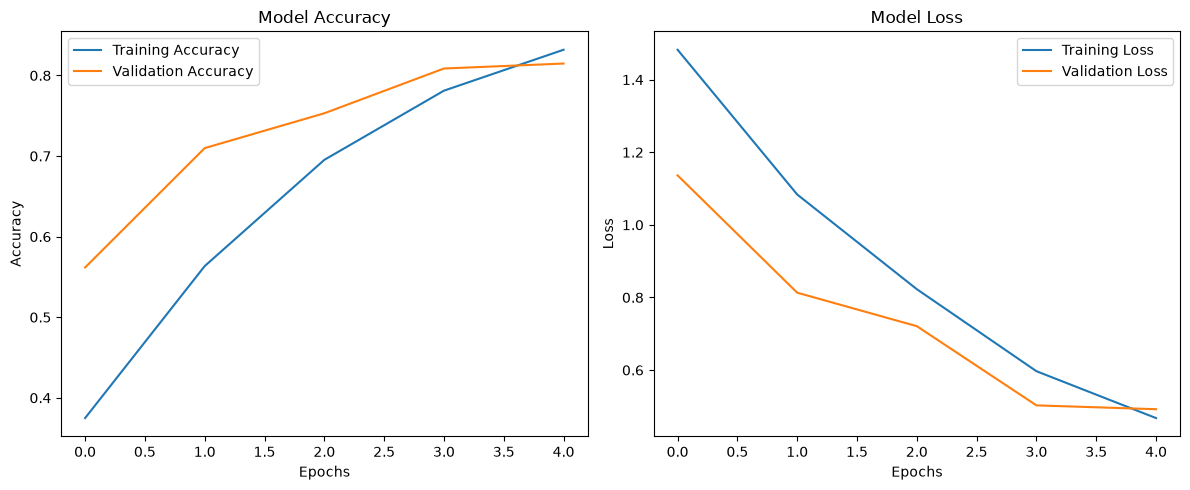

In [9]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

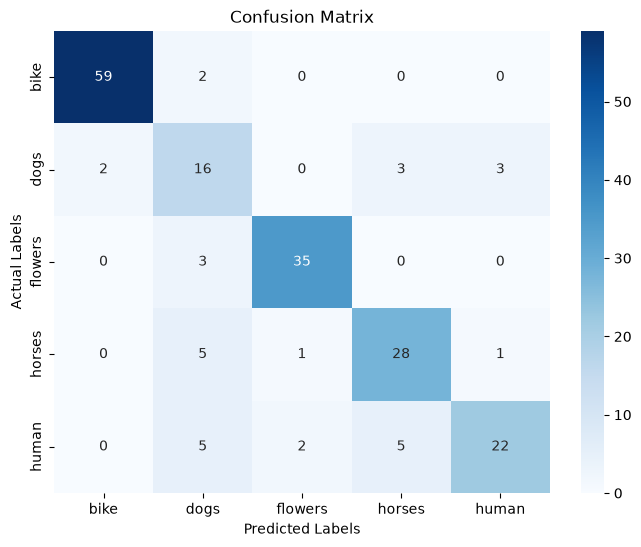

In [10]:
y_true = []
y_pred = []

for images, labels in test_ds:

    # Actual labels
    y_true.extend(np.argmax(labels.numpy(), axis=1))

    # Predicted labels
    predictions = model.predict(images, verbose=0)

    y_pred.extend(np.argmax(predictions, axis=1))

# Convert to NumPy arrays
y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted Labels')
plt.ylabel('Actual Labels')
plt.title('Confusion Matrix')

plt.show()

In [11]:
# Classification Report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

        bike       0.97      0.97      0.97        61
        dogs       0.52      0.67      0.58        24
     flowers       0.92      0.92      0.92        38
      horses       0.78      0.80      0.79        35
       human       0.85      0.65      0.73        34

    accuracy                           0.83       192
   macro avg       0.81      0.80      0.80       192
weighted avg       0.85      0.83      0.84       192



In [15]:
model.save("D:/Deep Learning for Image/models/multiclass_cnn_model.keras")

In [16]:
from tensorflow.keras.models import load_model
# Load trained model
model = load_model(
    "D:/Deep Learning for Image/models/multiclass_cnn_model.keras"
)

# Class names (must follow training dataset order)
class_names = ['bike', 'dogs', 'flowers', 'horses', 'human']

# Image path
image_path = "D:/Deep Learning for Image/Test_Images/test.jpg"

# Load and resize image
img = tf.keras.utils.load_img(
    image_path,
    target_size=(128, 128)
)

# Convert image to array
img_array = tf.keras.utils.img_to_array(img)

# Normalize pixel values
img_array = img_array / 255.0

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array)

# Get predicted class
predicted_index = np.argmax(prediction[0])

predicted_class = class_names[predicted_index]

confidence = prediction[0][predicted_index] * 100

print("Predicted Class:", predicted_class)
print("Confidence: {:.2f}%".format(confidence))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step
Predicted Class: human
Confidence: 91.03%


In [17]:
for i, class_name in enumerate(class_names):

    print(
        f"{class_name}: "
        f"{prediction[0][i] * 100:.2f}%"
    )

bike: 0.10%
dogs: 6.11%
flowers: 0.02%
horses: 2.74%
human: 91.03%


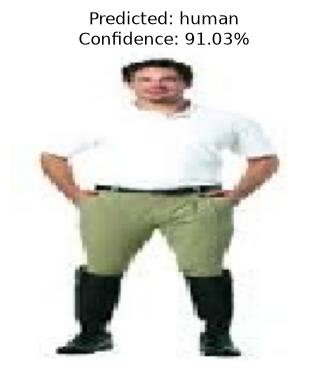

In [18]:
plt.figure(figsize=(4, 4))

plt.imshow(img)

plt.title(
    f"Predicted: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.axis('off')

plt.show()